# Healthcare Fraud Detection — Preprocessing and Baseline

## Preprocessing and Baseline Analysis

This notebook prepares the healthcare fraud dataset for modeling and establishes an initial baseline classifier.

The workflow includes:

1. Loading the audited dataset
2. Identifying the target and predictor variables
3. Preparing numerical and categorical features
4. Splitting the data into training and testing sets
5. Establishing a baseline model
6. Reporting preliminary evaluation results

In [2]:
import pandas as pd
import numpy as np

from pathlib import Path

data_path = Path("../data/raw/healthcare_fraud_detection.csv")
df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (10000, 20)


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0


In [3]:
target_column = "Is_Fraud"

identifier_columns = [
    "Claim_ID",
    "Patient_ID",
    "Provider_ID"
]

columns_to_drop = [
    target_column,
    *[column for column in identifier_columns if column in df.columns]
]

X = df.drop(columns=columns_to_drop)
y = df[target_column]

print("Target column:", target_column)
print("Dropped identifier columns:", columns_to_drop[1:])
print("Number of features remaining:", X.shape[1])

print("Target distribution:")
display(y.value_counts())

Target column: Is_Fraud
Dropped identifier columns: ['Claim_ID', 'Provider_ID']
Number of features remaining: 17
Target distribution:


Is_Fraud
0    9171
1     829
Name: count, dtype: int64

In [4]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nMissing values:")
display(X.isnull().sum().sort_values(ascending=False).head(10))

Numerical features:
['Patient_Age', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount', 'Days_Between_Service_and_Claim', 'Number_of_Claims_Per_Provider_Monthly', 'Length_of_Stay', 'Chronic_Condition_Flag', 'Prior_Visits_12m']

Categorical features:
['Patient_Gender', 'Diagnosis_Code', 'Insurance_Type', 'Claim_Submission_Date', 'Provider_Specialty', 'Patient_State', 'Claim_Status', 'Visit_Type']

Missing values:


Insurance_Type                    350
Prior_Visits_12m                  350
Provider_Specialty                350
Patient_Age                         0
Patient_Gender                      0
Claim_Amount                        0
Approved_Amount                     0
Procedure_Code                      0
Diagnosis_Code                      0
Days_Between_Service_and_Claim      0
dtype: int64

In [5]:
from sklearn.model_selection import train_test_split

# Split the data while preserving the fraud/non-fraud proportion
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8000, 17)
Testing features: (2000, 17)
Training target: (8000,)
Testing target: (2000,)


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Five-fold stratified cross-validation for the baseline
cv_baseline = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Naive benchmark: always predicts the most frequent class
dummy_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

# Generate out-of-fold predictions using training data only
y_oof_dummy = cross_val_predict(
    dummy_model,
    X_train,
    y_train,
    cv=cv_baseline,
    method="predict",
    n_jobs=-1
)

print("DummyClassifier five-fold out-of-fold results:")
print("Accuracy:", accuracy_score(y_train, y_oof_dummy))
print("Precision:", precision_score(y_train, y_oof_dummy, zero_division=0))
print("Recall:", recall_score(y_train, y_oof_dummy, zero_division=0))
print("F1-score:", f1_score(y_train, y_oof_dummy, zero_division=0))

print("\nClassification report:")
print(classification_report(y_train, y_oof_dummy, zero_division=0))

DummyClassifier five-fold out-of-fold results:
Accuracy: 0.917125
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      7337
           1       0.00      0.00      0.00       663

    accuracy                           0.92      8000
   macro avg       0.46      0.50      0.48      8000
weighted avg       0.84      0.92      0.88      8000



DummyClassifier out-of-fold confusion matrix:
[[7337    0]
 [ 663    0]]


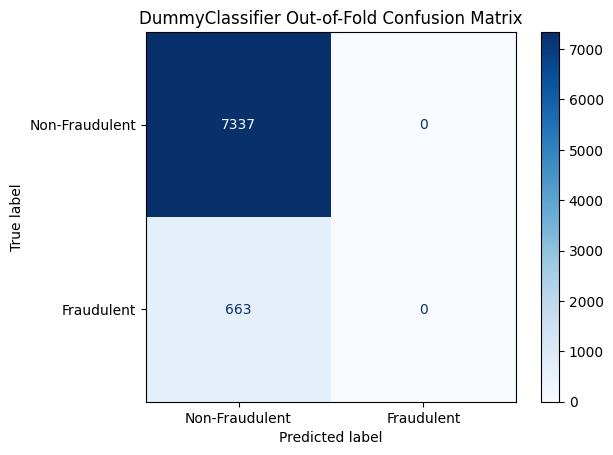

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# Calculate the out-of-fold DummyClassifier confusion matrix
cm_dummy = confusion_matrix(y_train, y_oof_dummy)

print("DummyClassifier out-of-fold confusion matrix:")
print(cm_dummy)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dummy,
    display_labels=["Non-Fraudulent", "Fraudulent"]
).plot(cmap="Blues")

plt.title("DummyClassifier Out-of-Fold Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

## DummyClassifier Benchmark: Confusion Matrix Interpretation

The DummyClassifier predicted every out-of-fold training observation as non-fraudulent (`0`).

It correctly classified 7,337 non-fraudulent claims but failed to identify any fraudulent claims. Therefore, all 663 fraudulent claims in the out-of-fold validation results were classified as false negatives.

The DummyClassifier achieved approximately 91.71% accuracy, but its fraud recall, precision, and F1-score were all zero. This confirms that accuracy alone is not sufficient for evaluating healthcare fraud detection.

Future models must also be evaluated using precision, recall, F1-score, PR-AUC, ROC-AUC, and confusion matrices.

## DummyClassifier Limitations and Next Steps

The DummyClassifier is a naive benchmark, not a useful fraud-detection model. It predicts every claim as non-fraudulent because that is the majority class, causing it to miss all fraudulent claims in the out-of-fold validation results.

The next stages of the project should:

1. Train supervised models that learn from the dataset features.
2. Address the class imbalance between fraudulent and non-fraudulent claims.
3. Compare models using accuracy, precision, recall, F1-score, PR-AUC, ROC-AUC, and confusion matrices.
4. Tune the classification threshold to prioritize fraud detection while controlling false positives.
5. Evaluate the final selected model once on the untouched test data.

## Interim Conclusion

The preprocessing workflow and DummyClassifier benchmark were completed successfully.

The DummyClassifier achieved approximately 91.71% accuracy because non-fraudulent claims were the majority class. However, it failed to identify any fraudulent claims. Therefore, it provides only a reference point and cannot be used as the final fraud-detection model.

Logistic Regression was evaluated using five-fold cross-validation and out-of-fold predictions. Its preliminary results will be compared with additional models and tuning strategies in the next stage.

## Logistic Regression: Initial Supervised Model

Logistic Regression was selected as the first supervised model because it learns relationships between the input features and the fraud target.

The model uses `class_weight="balanced"` so fraudulent cases receive more importance during training. This is appropriate because fraudulent cases are less common than non-fraudulent cases.

The model was evaluated using stratified five-fold cross-validation and out-of-fold predictions on the training data. Its preliminary results will be compared with additional models and tuning strategies using the same validation procedure.

After the final model and classification threshold are selected, the untouched test set will be used once for the final evaluation.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics for cross-validation
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Logistic Regression with balanced class weights
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Cross-validation on training data only
logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression five-fold cross-validation results:")

for metric in scoring:
    scores = logistic_cv_results[f"test_{metric}"]
    print(f"{metric.upper()}: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression five-fold cross-validation results:
ACCURACY: 0.9832 ± 0.0054
PRECISION: 0.8671 ± 0.0452
RECALL: 0.9456 ± 0.0195
F1: 0.9040 ± 0.0285
ROC_AUC: 0.9976 ± 0.0006
PR_AUC: 0.9804 ± 0.0039


In [22]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# Generate out-of-fold predicted probabilities on the training data
y_oof_prob = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Convert probabilities into class predictions using threshold 0.50
y_oof_pred = (y_oof_prob >= 0.50).astype(int)

# Evaluate OOF predictions
print("Logistic Regression out-of-fold results:")
print("Accuracy:", accuracy_score(y_train, y_oof_pred))
print("Precision:", precision_score(y_train, y_oof_pred, zero_division=0))
print("Recall:", recall_score(y_train, y_oof_pred, zero_division=0))
print("F1-score:", f1_score(y_train, y_oof_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_train, y_oof_prob))
print("PR-AUC:", average_precision_score(y_train, y_oof_prob))

print("\nOOF classification report:")
print(classification_report(y_train, y_oof_pred, zero_division=0))

Logistic Regression out-of-fold results:
Accuracy: 0.98325
Precision: 0.8648275862068966
Recall: 0.9457013574660633
F1-score: 0.9034582132564841
ROC-AUC: 0.9975984858249608
PR-AUC: 0.979974520665428

OOF classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      7337
           1       0.86      0.95      0.90       663

    accuracy                           0.98      8000
   macro avg       0.93      0.97      0.95      8000
weighted avg       0.98      0.98      0.98      8000



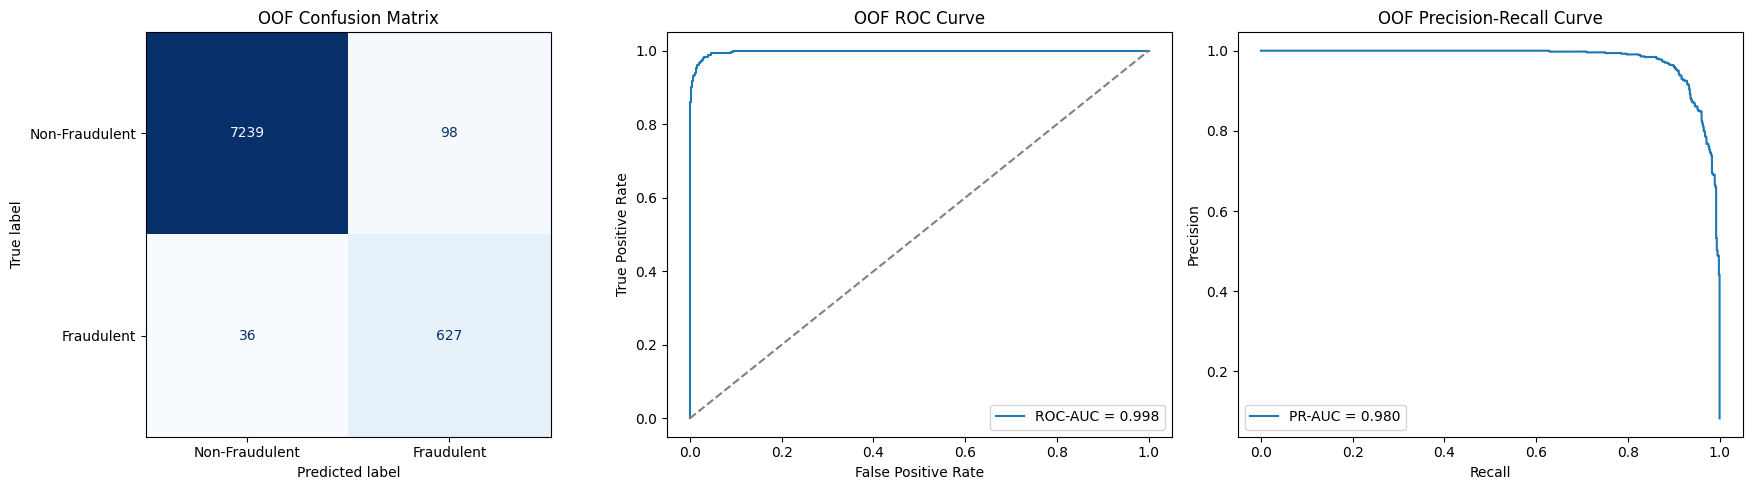

In [26]:
# Create plotting values
cm_oof = confusion_matrix(y_train, y_oof_pred)
fpr, tpr, _ = roc_curve(y_train, y_oof_prob)
precision, recall, _ = precision_recall_curve(y_train, y_oof_prob)

# Create three plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# OOF confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["Non-Fraudulent", "Fraudulent"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("OOF Confusion Matrix")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

# OOF ROC curve
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_train, y_oof_prob):.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("OOF ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

# OOF precision-recall curve
axes[2].plot(
    recall,
    precision,
    label=f"PR-AUC = {average_precision_score(y_train, y_oof_prob):.3f}"
)
axes[2].set_title("OOF Precision-Recall Curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()

plt.tight_layout()
plt.show()

## Logistic Regression OOF Results

The Logistic Regression model was evaluated using out-of-fold predictions across five stratified folds of the training data.

The model achieved:

- Accuracy: 0.983
- Precision: 0.865
- Recall: 0.945
- F1-score: 0.904
- ROC-AUC: 0.998
- PR-AUC: 0.980

These results indicate that the model identified most fraudulent cases while maintaining a relatively high precision. The PR-AUC is especially important because fraudulent cases are less common than non-fraudulent cases.

## OOF Confusion Matrix Interpretation

Using the default probability threshold of 0.50, the model correctly identified 627 fraudulent cases and missed 36 fraudulent cases.

The model also incorrectly classified 98 non-fraudulent cases as fraudulent. These false positives may require additional investigation.

The recall of approximately 0.945 means that the model detected about 94.5% of the fraudulent cases in the out-of-fold predictions. The precision of approximately 0.865 means that about 86.5% of the cases predicted as fraudulent were actually fraudulent.

## Current Project Status

The project has completed the following stages:

1. Dataset loading and target identification
2. Numerical and categorical feature identification
3. Train/test splitting
4. Preprocessing pipeline creation
5. DummyClassifier benchmark
6. Balanced Logistic Regression
7. Five-fold cross-validation
8. Out-of-fold predictions
9. Confusion matrix, ROC curve, and precision-recall curve analysis

The Logistic Regression results are promising, but this model has not yet been selected as the final model.

## Future Modeling Plan

The next steps are:

1. Train and evaluate tree-based models using the same cross-validation strategy.
2. Compare Logistic Regression with the tree-based models using recall, precision, F1-score, ROC-AUC, and PR-AUC.
3. Apply RandomizedSearchCV to explore a broad range of tree-model hyperparameters.
4. Apply focused GridSearchCV around the best-performing region.
5. Select the final model using cross-validation results.
6. Fit the selected model on all training data.
7. Evaluate the final model once on the untouched test set.
8. Analyze the final confusion matrix and probability-based plots.